# 02 — Measuring a model's quality: from likelihood to loss

**Chapter 1** · suggested time: 25 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_1/02_measuring_the_loss.ipynb)

![Chapter roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/00_roadmap.png)

**What we can do so far:** count the transitions, get a table `P`, then generate names.

**What we are missing:** a way to say **objectively** whether one probability table is better than another. "The names look nice" is not a measurement.

We are going to build a **quality thermometer**: a single number that measures how compatible a model's predictions are with the real names.

> **Why this is essential for what follows:** in notebook 03, we will replace `P` with a weight matrix `W` drawn at random. To train it, we will need a number to **minimize**. That is the number we build here: the **loss**.

**The path, in five steps:**
1. look at the probability given to the **correct answer**;
2. extend it to all the letters of a name: the *likelihood*;
3. go from a product to a sum: the *log-likelihood*;
4. flip the sign to get a cost: the *negative log-likelihood* (NLL);
5. average over the whole corpus: **the loss**.

In [1]:
# On Google Colab: fetch the course repository (corpus + shared modules such as bigram.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("bigram.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_1

In [2]:
# Setup: imports and the chapter's small shared module
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigram  # file bigram.py, next to this notebook
from bigram import SEED, plot_char_matrix

words = bigram.load_names()
chars, stoi, itos = bigram.build_vocabulary(words)
print(f"{len(words):,} names · vocabulary of {len(stoi)} symbols · PyTorch {torch.__version__}")

N = bigram.count_bigrams(words, stoi)
P = N.float() / N.sum(dim=1, keepdim=True)     # the table from notebook 01

32,033 names · vocabulary of 27 symbols · PyTorch 2.15.0+cu132


## 1. A more reliable test: the probability of the correct answer

Let's ask the model a question: **"I am at the start of a name (`.`); what is the first letter?"**

The model does not answer "`e`". It proposes **27 probabilities**, one per possible character. For the name `emma`, the true answer is `e`.

First measurement: **what probability did the model give to the true answer?**

$$
\underbrace{P(e\mid .)}_{\text{probability of the true answer}}
=\frac{\overbrace{N[\texttt{.},\texttt{e}]}^{\text{names starting with e}}}{\underbrace{\textstyle\sum_j N[\texttt{.},j]}_{\text{total number of names}}}.
$$

In [3]:
i, j = stoi["."], stoi["e"]
print(f"Out of {N[i].sum().item()} names, {N[i, j].item()} start with 'e'.")
print(f"P(e | .) = {P[i, j].item():.4f}   ({100 * P[i, j].item():.2f}%)")
print(f"A uniform model would give 1/27 = {1/27:.4f}")

Out of 32033 names, 1531 start with 'e'.
P(e | .) = 0.0478   (4.78%)
A uniform model would give 1/27 = 0.0370


**Careful with the interpretation:** 0.0478 means "about 4.8% of the names in the corpus start with `e`". It is **not** the probability that `emma` is a good name.

Here 0.048 > 1/27 ≈ 0.037: on this question, the model does a bit better than chance. But a single question is not enough to judge: we must look at **all** the predictions.

## 2. A name contains several predictions: the *likelihood*

![Scoring the model on emma](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/02_nll_emma.png)

For `emma`, the model answers **five questions**:
` . → e ` · ` e → m ` · ` m → m ` · ` m → a ` · ` a → . `

To get the probability the model assigns to the **whole** sequence `.emma.`, we **multiply** the five conditional probabilities. This is the probability rule for a sequence of events. In a bigram, each factor only depends on the previous character:

$$
L(\texttt{emma}) = P(e\mid .)\,P(m\mid e)\,P(m\mid m)\,P(a\mid m)\,P(.\mid a).
$$

The *likelihood* is the probability that **our model** assigns to this exact sequence. It does not say whether the name is "pretty". It lets us **compare two models on the same observation**.

In [4]:
sequence = ["."] + list("emma") + ["."]
probabilities, labels = [], []

print("Transition | count / total | p(correct answer)")
print("-" * 48)
for ch1, ch2 in zip(sequence, sequence[1:]):
    i, j = stoi[ch1], stoi[ch2]
    p = P[i, j].item()
    probabilities.append(p)
    labels.append(f"{ch1} → {ch2}")
    print(f"  {ch1} → {ch2}    | {N[i, j].item():5d} / {N[i].sum().item():5d} | {p:.4f}")

likelihood_emma = math.prod(probabilities)
print(f"\nLikelihood L('emma')         = {likelihood_emma:.3e}")
print(f"Likelihood, uniform model    = {(1/27)**5:.3e}")
print(f"Our table makes 'emma' {likelihood_emma / (1/27)**5:.0f} times more probable than the uniform model.")

Transition | count / total | p(correct answer)
------------------------------------------------
  . → e    |  1531 / 32033 | 0.0478
  e → m    |   769 / 20423 | 0.0377
  m → m    |   168 /  6642 | 0.0253
  m → a    |  2590 /  6642 | 0.3899
  a → .    |  6640 / 33885 | 0.1960

Likelihood L('emma')         = 3.478e-06
Likelihood, uniform model    = 6.969e-08
Our table makes 'emma' 50 times more probable than the uniform model.


## 3. Why switch to the logarithm?

We would like to **maximize** the likelihood of **the whole corpus**: the product of the probabilities of its 228,146 transitions. But multiplying hundreds of thousands of numbers smaller than 1 gives a result so small that the computer can no longer represent it. We say it **rounds down to zero** (*underflow*). Let's try.

In [5]:
xs_all, ys_all = bigram.build_examples(words, stoi)
p_true = P[xs_all, ys_all]          # the probability of each true transition in the corpus

for n in [10, 100, 1000, len(p_true)]:
    product = torch.prod(p_true[:n])
    sum_logs = p_true[:n].log().sum()
    print(f"{n:>7} transitions: product = {product.item():.3e}   sum of logs = {sum_logs.item():12.2f}")

     10 transitions: product = 3.191e-12   sum of logs =       -26.47
    100 transitions: product = 0.000e+00   sum of logs =      -239.92
   1000 transitions: product = 0.000e+00   sum of logs =     -2371.76


 228146 transitions: product = 0.000e+00   sum of logs =   -559873.62


From 100 transitions on, the product is **0** in float32: it can no longer compare anything. The sum of the logarithms, on the other hand, remains a perfectly readable number.

This is the key property of the logarithm:

$$
\log(a\times b\times c) = \log a+\log b+\log c
\qquad\Rightarrow\qquad
\log L(\texttt{emma}) = \log P(e\mid .)+\log P(m\mid e)+\cdots+\log P(.\mid a).
$$

**Three good reasons to switch to the log:**
1. **Numerical stability:** a sum does not collapse to zero.
2. **The ranking of models does not change:** `log` is strictly increasing. If `L_A > L_B` then `log L_A > log L_B`.
3. **Easier to differentiate:** the derivative of a sum is the sum of the derivatives. This will be valuable in notebook 05.

**Why are these logarithms negative?** Probabilities lie between 0 and 1. Now `log(1) = 0` and `log(0.1) ≈ −2.30`. The smaller the probability of the correct answer, the more negative its logarithm.

In [6]:
log_likelihood_emma = sum(math.log(p) for p in probabilities)
print(f"log of the likelihood       : {math.log(likelihood_emma):+.4f}")
print(f"sum of the log-probabilities: {log_likelihood_emma:+.4f}   (identical)")

log of the likelihood       : -12.5690
sum of the log-probabilities: -12.5690   (identical)


## 4. A score to maximize becomes a *loss* to minimize

We want to **maximize** the log-likelihood. But gradient descent (notebook 05) **minimizes** a cost. We simply flip the sign:

$$
\boxed{\text{cost of an observed transition} = -\log(p_\text{true answer})}
$$

This is the **negative log-likelihood (NLL)**.

| p of the true answer | cost `−log p` | interpretation |
|---:|---:|---|
| 1.00 | 0.00 | the model was certain of the correct answer |
| 0.80 | 0.22 | it found it very plausible |
| 0.10 | 2.30 | it found it unlikely |
| 0.01 | 4.61 | it was very surprised |
| → 0 | → ∞ | it considered it impossible |

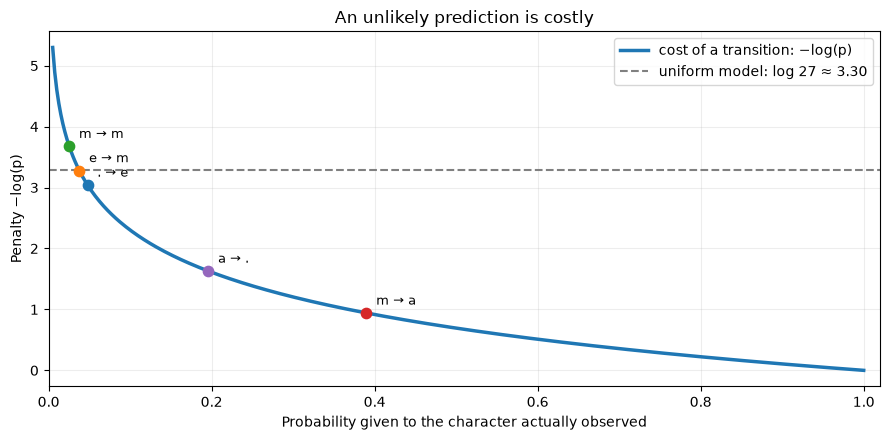

In [7]:
p_grid = torch.linspace(0.005, 1, 400)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(p_grid.numpy(), -p_grid.log().numpy(), linewidth=2.5, label="cost of a transition: −log(p)")
for label, p in zip(labels, probabilities):
    ax.scatter(p, -math.log(p), s=55, zorder=4)
    ax.annotate(label, (p, -math.log(p)), xytext=(7, 6), textcoords="offset points", fontsize=9)
ax.axhline(math.log(27), color="gray", linestyle="--", label="uniform model: log 27 ≈ 3.30")
ax.set(xlabel="Probability given to the character actually observed", ylabel="Penalty −log(p)",
       title="An unlikely prediction is costly", xlim=(0, 1.02))
ax.grid(alpha=0.22); ax.legend(); plt.tight_layout(); plt.show()

**Question:** on which transitions of `emma` is the model penalized the most? On `m → m`, `e → m` and `. → e`, to which it gives a low probability. The `m → m` transition even costs more than with a uniform model (3.68 > 3.30): a double `m` is rare in the corpus.

## 5. A single score over the whole corpus: the mean NLL

We proceed as for an exam with many questions:
1. for **each real transition** in the corpus, read the probability of the true answer in `P`;
2. compute its cost `−log p`;
3. **average**, to get a score per prediction that does not grow with the size of the corpus.

$$
\boxed{\mathcal{L}(P)=-\frac{1}{M}\sum_{t=1}^{M}\log P(y_t\mid x_t)}
$$

- `M`: total number of observed **bigrams** (not the number of names);
- `x_t`: current character of transition `t`; `y_t`: the true next character.

**The lower the mean NLL, the better the model.** To know whether our score is good, we compare it with the **uniform** model, whose loss is always `−log(1/27) = log 27 ≈ 3.30`.

In [8]:
total_nll, M = 0.0, 0
for name in words:
    sequence = ["."] + list(name) + ["."]
    for ch1, ch2 in zip(sequence, sequence[1:]):
        total_nll += -math.log(P[stoi[ch1], stoi[ch2]].item())
        M += 1

counting_loss = total_nll / M
print(f"Transitions evaluated : {M:,}")
print(f"Uniform model loss    : {math.log(27):.4f}")
print(f"Loss of our table P   : {counting_loss:.4f}")

# The same thing in one line, without a Python loop (we will explain this indexing in notebook 05):
print(f"Vectorized version    : {-P[xs_all, ys_all].log().mean().item():.4f}")

Transitions evaluated : 228,146
Uniform model loss    : 3.2958
Loss of our table P   : 2.4540
Vectorized version    : 2.4540


The table `P` scores **2.45**, versus **3.30** for the uniform model. Careful: this score is measured **on the data that was used for counting**. It is not yet proof that the model **generalizes** to names it has never seen (we will separate train and validation in chapter 2).

### Another reading: perplexity

`exp(loss)` is called the **perplexity**. You can read it as the number of characters the model hesitates between "on average" at each prediction.

In [9]:
print(f"Uniform perplexity: {math.exp(math.log(27)):.1f}  (hesitates between 27 characters)")
print(f"Perplexity of P   : {math.exp(counting_loss):.1f}  (hesitates as if between ~{math.exp(counting_loss):.0f} characters)")

Uniform perplexity: 27.0  (hesitates between 27 characters)
Perplexity of P   : 11.6  (hesitates as if between ~12 characters)


## 6. The zero trap, and smoothing

What happens for a name that contains a transition **never seen** in the corpus? The count is 0, so the probability is 0, and the cost `−log 0` is **infinite**.

In [10]:
def name_nll(name, table):
    seq = ["."] + list(name) + ["."]
    costs = [-math.log(table[stoi[a], stoi[b]].item()) if table[stoi[a], stoi[b]] > 0 else float("inf")
             for a, b in zip(seq, seq[1:])]
    return sum(costs) / len(costs)

print("N['j', 'q'] =", N[stoi['j'], stoi['q']].item())
print("NLL of 'andrejq' with P:", name_nll("andrejq", P))

N['j', 'q'] = 0
NLL of 'andrejq' with P: inf


A single unknown bigram makes the loss infinite: the model declares "impossible" something that happened. The classic fix is called **smoothing**. We add a **fake count** to every cell, for example `N + 1` (Laplace smoothing). Then no probability is zero.

In [11]:
P_smooth = (N + 1).float() / (N + 1).sum(dim=1, keepdim=True)
print("NLL of 'andrejq' with smoothed P:", round(name_nll("andrejq", P_smooth), 4))
print("Corpus loss, P                  :", round(-P[xs_all, ys_all].log().mean().item(), 4))
print("Corpus loss, smoothed P         :", round(-P_smooth[xs_all, ys_all].log().mean().item(), 4))
for k in [10, 1000, 100_000]:
    Pk = (N + k).float() / (N + k).sum(dim=1, keepdim=True)
    print(f"  smoothing +{k:<7}: loss = {-Pk[xs_all, ys_all].log().mean().item():.4f}")

NLL of 'andrejq' with smoothed P: 3.4834


Corpus loss, P                  : 2.454
Corpus loss, smoothed P         : 2.4546


  smoothing +10     : loss = 2.4621
  smoothing +1000   : loss = 2.8523


  smoothing +100000 : loss = 3.2837


Smoothing +1 costs almost nothing on the corpus (2.4546 instead of 2.4540), and removes the infinities. The more fake counts we add, the closer each row gets to **uniform**, and the more the loss climbs back toward 3.30. We will meet this idea again in notebook 06, under the name **regularization**.

## Summary: the essential link with what follows

We now have **two distinct things**:
- **a model** (`P`): for a current character, it predicts 27 probabilities;
- **a criterion** (the mean NLL): from these probabilities and the **true answers**, it produces a single number.

The table `P` was obtained by counting: **nothing was trained**.

**The question that kicks off what follows:** what if the probabilities no longer came from counts, but from a weight matrix `W` drawn at random? **How do we change `W` to decrease this same loss?**

> The loss is not specific to the bigram. It is **the learning signal** we will reuse when the probabilities are produced by a neural network, then by a Transformer (in chapter 2, `F.cross_entropy` computes exactly this mean NLL).

## References
- D. Jurafsky and J. H. Martin, [*Speech and Language Processing*](https://web.stanford.edu/~jurafsky/slp3/), chapter 3: evaluation with perplexity (3.3) and Laplace smoothing (3.6).
- I. Goodfellow, Y. Bengio and A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), 2016, section 5.5 "Maximum Likelihood Estimation".
- Andrej Karpathy, [*The spelled-out intro to language modeling: building makemore*](https://www.youtube.com/watch?v=PaCmpygFfXo) (2022) and the [makemore](https://github.com/karpathy/makemore) repository, where `names.txt` and the spirit of this chapter come from.